In [1]:
import cudf
import cuml
import cupy as cp
import matplotlib.pyplot as plt
import seaborn as sns
from cuml.model_selection import train_test_split
from cuml.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, RobustScaler
from cuml.decomposition import PCA
from cuml.cluster import DBSCAN
from sklearn.metrics import (confusion_matrix, precision_score,
                           recall_score, f1_score, accuracy_score,
                           roc_auc_score)
from sklearn.model_selection import ParameterGrid
import numpy as np
import warnings
import kagglehub
warnings.filterwarnings('ignore')


In [2]:
cuml.set_global_output_type('cupy')

In [3]:
def draw_confusion_matrix(cm, title='Confusion Matrix'):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Fraud', 'Fraud'],
                yticklabels=['Not Fraud', 'Fraud'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [4]:
def print_confusion_matrix(cm, title):
    print(f"{title}:")
    print("         Predicted")
    print("         Not Fraud  Fraud")
    print("Actual")
    print(f"Not Fraud  {cm[0,0]:6d}  {cm[0,1]:6d}")
    print(f"Fraud      {cm[1,0]:6d}  {cm[1,1]:6d}")

In [5]:
def plot_pca_clusters(pca_df, title):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='PC1', y='PC2', hue='fraud', style='fraud',
                    data=pca_df.to_pandas(), palette='viridis')
    plt.title(title)
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.show()

In [6]:
def load_and_preprocess_data():
    path = kagglehub.dataset_download("ealaxi/banksim1")
    data = cudf.read_csv(path + '/bs140513_032310.csv')

    # Clean and transform data
    data = data.drop(['zipcodeOri', 'zipMerchant'], axis=1)
    for col in ['customer', 'age', 'gender', 'merchant']:
        data[col] = data[col].str[1:-1]
    data['category'] = data['category'].str.replace('es_', '')
    data = data[data['gender'] != 'U']
    data['age'] = data['age'].replace('U', '7').astype('float32')
    data['amount'] = data['amount'].astype('float32')

    # Create amount thresholds
    bins = [0, 500, 1000, 1500, 2000, 2500, 3000, float('inf')]
    labels = ['0-500', '500-1000', '1000-1500', '1500-2000',
              '2000-2500', '2500-3000', '>3000']
    data['amount_thresh'] = cudf.cut(data['amount'], bins=bins, labels=labels)

    # Feature engineering
    for entity in ['customer', 'merchant', 'category', 'amount_thresh']:
        freq = data.groupby(entity).size().reset_index(name=f'{entity}_freq')
        freq[f'{entity}_ID'] = cp.arange(1, len(freq) + 1)
        data = data.merge(freq, on=entity)
        if entity in ['customer', 'merchant']:
            data = data.drop(entity, axis=1)
        else:
            data[entity] = data[f'{entity}_ID']
            data = data.drop(f'{entity}_ID', axis=1)

    # Normalize frequencies
    total = len(data)
    for col in data.columns:
        if '_freq' in col:
            data[col] = (data[col] / total * 100).round(5)

    # One-hot encoding
    ohe = OneHotEncoder(sparse=True, handle_unknown='ignore')
    ohe_cols = ['age', 'gender', 'category', 'amount_thresh']
    ohe_data = ohe.fit_transform(data[ohe_cols])
    ohe_data = cudf.DataFrame(ohe_data.toarray(),
                             columns=ohe.get_feature_names(ohe_cols))
    data = cudf.concat([data.drop(ohe_cols, axis=1), ohe_data], axis=1)

    # Label encoding for target
    le = LabelEncoder()
    data['fraud'] = le.fit_transform(data['fraud'])

    return data

In [7]:
def evaluate_dbscan(params, X_train, y_train, X_test, y_test):
    scaler = RobustScaler()  # Changed from StandardScaler
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Use PCA for better clustering
    pca = PCA(n_components=5)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)

    dbscan = DBSCAN(
        eps=params['eps'],
        min_samples=params['min_samples'],
        output_type='cupy'
    )

    train_labels = dbscan.fit_predict(X_train_pca)
    test_labels = dbscan.fit_predict(X_test_pca)

    # Dynamic fraud thresholding (adjust based on cluster size)
    def analyze_clusters(labels, true_labels):
        clusters = cudf.DataFrame({'cluster': labels, 'true_label': true_labels})
        stats = []
        for cluster in cp.unique(labels).get():
            if cluster == -1:  # Noise
                continue
            mask = clusters['cluster'] == cluster
            fraud_ratio = clusters[mask]['true_label'].mean()
            size = len(clusters[mask])

            # Dynamic threshold: smaller clusters can have higher fraud ratios
            threshold = params['fraud_threshold']
            if size > 100:
                threshold *= 0.8  # Be stricter for large clusters
            stats.append({
                'cluster': cluster,
                'fraud_ratio': fraud_ratio,
                'size': size,
                'is_fraud': fraud_ratio > threshold
            })
        return cudf.DataFrame(stats)

    train_stats = analyze_clusters(train_labels, y_train)
    cluster_mapping = {
        row.cluster: 1 if row.is_fraud else 0
        for row in train_stats.to_pandas().itertuples()
    }
    cluster_mapping[-1] = 0  # Noise points as non-fraud

    # Evaluation function
    def evaluate(y_true, labels, name):
        pred = cudf.Series(labels).map(cluster_mapping).fillna(0)
        # Convert to numpy arrays correctly
        y_true_np = y_true.to_array() if hasattr(y_true, 'to_array') else y_true.values.get()
        y_pred_np = pred.to_array() if hasattr(pred, 'to_array') else pred.values.get()

        metrics = {
            'cm': confusion_matrix(y_true_np, y_pred_np),
            'recall': recall_score(y_true_np, y_pred_np),
            'precision': precision_score(y_true_np, y_pred_np),
            'f1': f1_score(y_true_np, y_pred_np),
            'accuracy': accuracy_score(y_true_np, y_pred_np),
            'auc': roc_auc_score(y_true_np, y_pred_np)
        }

        print(f"\n=== {name} Results ===")
        print_confusion_matrix(metrics['cm'], f"{name} Confusion Matrix")
        print(f"Recall: {metrics['recall']:.4f} | Precision: {metrics['precision']:.4f}")
        print(f"F1: {metrics['f1']:.4f} | AUC: {metrics['auc']:.4f}")

        return metrics

    # Evaluate both sets
    train_metrics = evaluate(y_train, train_labels, "Training")
    test_metrics = evaluate(y_test, test_labels, "Test")

    return {
        'params': params,
        'train_metrics': train_metrics,
        'test_metrics': test_metrics,
        'cluster_stats': train_stats,
        'model': dbscan,
        'scaler': scaler
    }

In [8]:
def main():
    # Load and preprocess data
    data = load_and_preprocess_data()
    print("Data dimensions:", data.shape)

    # PCA visualization
    pca_cols = [col for col in data.columns if col != 'fraud']
    scaler = StandardScaler()
    pca_data = PCA(n_components=2).fit_transform(scaler.fit_transform(data[pca_cols]))
    pca_df = cudf.DataFrame(pca_data, columns=['PC1', 'PC2'])
    pca_df['fraud'] = data['fraud']
    plot_pca_clusters(pca_df, 'Fraud Spread over Principal Components')

    # Train-test split
    X = data.drop('fraud', axis=1)
    y = data['fraud']
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=123, stratify=y)

    param_grid = {
    'eps': [3.2, 3.5, 3.8],          # Focused around best-performing eps (3.0-4.0)
    'fraud_threshold': [0.06, 0.07, 0.08] , # Tight range around 0.08 (best observed)
    'min_samples': [2, 3, 4],         # Lower values favor fraud detection
}
    results = []
    for params in ParameterGrid(param_grid):
        print(f"\nEvaluating: {params}")
        result = evaluate_dbscan(params, X_train, y_train, X_test, y_test)
        results.append(result)

    # Find best model by test F1 score
    best_result = max(results, key=lambda x: x['test_metrics']['f1'])
    print("\n=== BEST MODEL ===")
    print(f"Parameters: eps={best_result['params']['eps']}, "
          f"min_samples={best_result['params']['min_samples']}, "
          f"threshold={best_result['params']['fraud_threshold']}")
    print(f"Test F1: {best_result['test_metrics']['f1']:.4f} | "
          f"Recall: {best_result['test_metrics']['recall']:.4f}")

    return best_result

Data dimensions: (594076, 42)


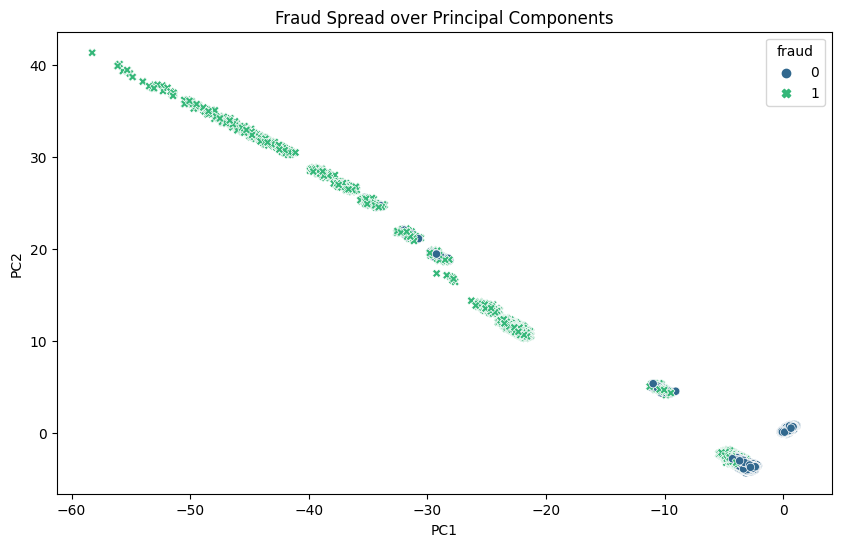


Evaluating: {'eps': 3.2, 'fraud_threshold': 0.06, 'min_samples': 2}
[2025-07-12 02:58:51.793] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 5674 -> 4819. Using the larger integer type might result in better performance
[2025-07-12 03:02:08.621] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 17041 -> 14459. Using the larger integer type might result in better performance

=== Training Results ===
Training Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud  378644   61513
Fraud          22    5378
Recall: 0.9959 | Precision: 0.0804
F1: 0.1488 | AUC: 0.9281

=== Test Results ===
Test Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud  125983   20736
Fraud          35    1765
Recall: 0.9806 | Precision: 0.0784
F1: 0.1453 | AUC: 0.9196

Evaluating: {'eps': 3.2, 'fraud_threshold': 0.06, 'min_samples': 3}
[2025-07-12 03:02:33.220] [CUML] [warning] Batch size limited by the chosen 

In [ ]:
best_model = main()